# PROYECTO: Análisis de Datos de Wearables (Fitbit)

Semana 1: Carga de datos y exploración inicial

Objetivo de esta semana:
- Cargar todos los CSVs del dataset de Kaggle (Fitbit Fitness Tracker Data)
- Entender la estructura de cada tabla (filas, columnas, tipos, nulos, duplicados)
- Generar un primer diagnóstico de calidad de datos antes de limpiar nada

In [1]:
import pandas as pd
import os
from pathlib import Path

1. CONFIGURACIÓN

In [2]:
RAW_DATA_PATH = Path("data/raw")
OUTPUT_PATH = Path("outputs")
OUTPUT_PATH.mkdir(exist_ok=True)

#crea la dirección de la ruta de la data con el nombre "Path"
#guarda los resultados
#crea la carpeta solo si aún no existe ("exist_ok=True" es para que no truene si es que sí existe la carpeta)

Diccionario de archivos esperados

In [3]:
ARCHIVOS = {
    "actividad_diaria": "dailyActivity_merged.csv",
    "sueno": "sleepDay_merged.csv",
}

#renombrar archivos

Encontrar archivos duplicados

In [4]:
def variantes_de_archivo(nombre_base):
    stem = Path(nombre_base).stem
    ext = Path(nombre_base).suffix
    variantes = [nombre_base]
    for i in range(2, 5):
        variantes.append(f"{stem} ({i}){ext}")
    return variantes

#stem te da el nombre del archivo SIN extensiones (.csv)
#.suffix te da solamente la extensión (".csv")
# ".append() agrega el bucle a la lista "variantes"
#Path convierte un texto normal en un objeto especial para manejar rutas y nombres de archivo

#La f antes de las comillas le dice a Python: "dentro de este texto,
#        todo lo que esté entre { } no lo trates como texto literal,
#        evalúalo como código y mete el resultado ahí".

In [5]:
def cargar_datasets(archivos: dict, ruta_base: Path) -> dict:
    dataframes = {}
    print("=" * 60)
    print("CARGANDO DATASETS")
    print("=" * 60)

    for nombre, archivo_base in archivos.items():
        piezas = []
        archivos_encontrados = []

        for variante in variantes_de_archivo(archivo_base):
            ruta = ruta_base / variante
            if ruta.exists():
                df_parte = pd.read_csv(ruta)
                df_parte["periodo_origen"] = variante
                #agrega una columna con el nombre del archivo del que vino cada fila
                piezas.append(df_parte)
                archivos_encontrados.append(variante)
                #.append guardan la tabla y el nombre en las listas

        if piezas:
            df = pd.concat(piezas, ignore_index=True)
            dataframes[nombre] = df
            archivos_str = " + ".join(archivos_encontrados)
            print(f"✅ {nombre:25s} -> {df.shape[0]:>6} filas, {df.shape[1]:>2} columnas  ({archivos_str})")
        else:
            print(f"⚠️  {nombre:25s} -> ningún archivo encontrado para: {archivo_base}")

    return dataframes



In [6]:
def diagnostico_calidad(df, nombre):
    resumen = pd.DataFrame({
        "tipo_dato": df.dtypes,
        "nulos": df.isnull().sum(),
        "pct_nulos": (df.isnull().sum() / len(df) * 100).round(2),
        "valores_unicos": df.nunique(),
    })

    columnas_comparar = [c for c in df.columns if c != "periodo_origen"]

    print(f"\n--- Diagnóstico: {nombre} ---")
    print(f"Filas totales: {len(df)}")
    print(f"Filas duplicadas: {df.duplicated(subset=columnas_comparar).sum()}")
    print(f"Usuarios únicos: {df['Id'].nunique()}")
    print(resumen)

    return resumen

In [7]:
dataframes = cargar_datasets(ARCHIVOS, RAW_DATA_PATH)
for nombre, df in dataframes.items():
    diagnostico_calidad(df, nombre)

CARGANDO DATASETS
✅ actividad_diaria          ->   1397 filas, 16 columnas  (dailyActivity_merged.csv + dailyActivity_merged (2).csv)
✅ sueno                     ->    413 filas,  6 columnas  (sleepDay_merged.csv)

--- Diagnóstico: actividad_diaria ---
Filas totales: 1397
Filas duplicadas: 0
Usuarios únicos: 35
                         tipo_dato  nulos  pct_nulos  valores_unicos
Id                           int64      0        0.0              35
ActivityDate                object      0        0.0              62
TotalSteps                   int64      0        0.0            1208
TotalDistance              float64      0        0.0             781
TrackerDistance            float64      0        0.0             780
LoggedActivitiesDistance   float64      0        0.0              35
VeryActiveDistance         float64      0        0.0             410
ModeratelyActiveDistance   float64      0        0.0             243
LightActiveDistance        float64      0        0.0             5

In [8]:
act = dataframes["actividad_diaria"].copy()
sue = dataframes["sueno"].copy()
#sacan las dos tablas del diccionario y trabajan sobre copias,
#    así que dataframes queda intacto

act["fecha"] = pd.to_datetime(act["ActivityDate"], format="%m/%d/%Y")
sue["fecha"] = pd.to_datetime(sue["SleepDay"], format="%m/%d/%Y %I:%M:%S %p")

print(act["fecha"].min(), "->", act["fecha"].max())
print(sue["fecha"].min(), "->", sue["fecha"].max())
print("Usuarios en sueño:", sue["Id"].nunique())
print("Duplicados usuario-día en actividad:", act.duplicated(subset=["Id", "fecha"]).sum())
print("Duplicados usuario-día en sueño:", sue.duplicated(subset=["Id", "fecha"]).sum())

#cuenta las filas donde se repite la misma combinación de usuario y día,
#       aunque los demás valores sean distintos.

2016-03-12 00:00:00 -> 2016-05-12 00:00:00
2016-04-12 00:00:00 -> 2016-05-12 00:00:00
Usuarios en sueño: 24
Duplicados usuario-día en actividad: 24
Duplicados usuario-día en sueño: 3


ver las filas donde el mismo usuario aparece dos veces en el mismo día en actividad, y revisar en qué fecha y de qué archivo vienen, para decidir cómo limpiarlas.

In [9]:
dup = act[act.duplicated(subset=["Id", "fecha"], keep=False)].sort_values(["Id", "fecha"])
print(dup["fecha"].value_counts().head())
print(dup["periodo_origen"].value_counts())
dup[["Id", "fecha", "TotalSteps", "Calories", "periodo_origen"]].head(10)

fecha
2016-04-12    48
Name: count, dtype: int64
periodo_origen
dailyActivity_merged.csv        24
dailyActivity_merged (2).csv    24
Name: count, dtype: int64


,Id,fecha,TotalSteps,Calories,periodo_origen
18,1503960366,2016-04-12,224,50,dailyActivity_merged.csv
457,1503960366,2016-04-12,13162,1985,dailyActivity_merged (2).csv
37,1624580081,2016-04-12,6627,706,dailyActivity_merged.csv
488,1624580081,2016-04-12,8163,1432,dailyActivity_merged (2).csv
59,1844505072,2016-04-12,0,399,dailyActivity_merged.csv
549,1844505072,2016-04-12,6697,2030,dailyActivity_merged (2).csv
71,1927972279,2016-04-12,24,942,dailyActivity_merged.csv
580,1927972279,2016-04-12,678,2220,dailyActivity_merged (2).csv
83,2022484408,2016-04-12,6717,1140,dailyActivity_merged.csv
611,2022484408,2016-04-12,11875,2390,dailyActivity_merged (2).csv


limpiar:

In [10]:
#en el traslape del 12-abr, conserva la fila con más pasos (día completo)
act = act.sort_values("TotalSteps", ascending=False).drop_duplicates(subset=["Id", "fecha"], keep="first")

# Sueño: quita las 3 filas idénticas
sue = sue.drop_duplicates(subset=["Id", "fecha"])

print(len(act), len(sue))

#drop_duplicates(..., keep="first") deja solo la primera fila de cada usuario-día, o sea la de más pasos

1373 410


unir:

In [11]:
df = act.merge(sue, on=["Id", "fecha"], how="inner")
print(df.shape)
print("Usuarios en la tabla final:", df["Id"].nunique())

#merge(..., on=["Id", "fecha"], how="inner") pega actividad y sueño por usuario y fecha,
#     y se queda solo con los días que tienen ambos

(410, 22)
Usuarios en la tabla final: 24


Gráficas

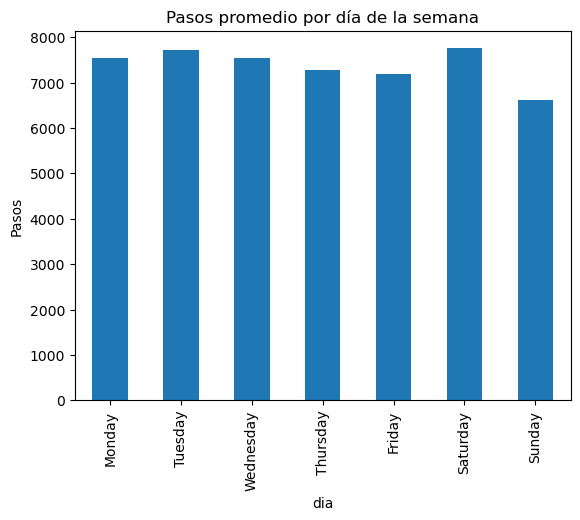

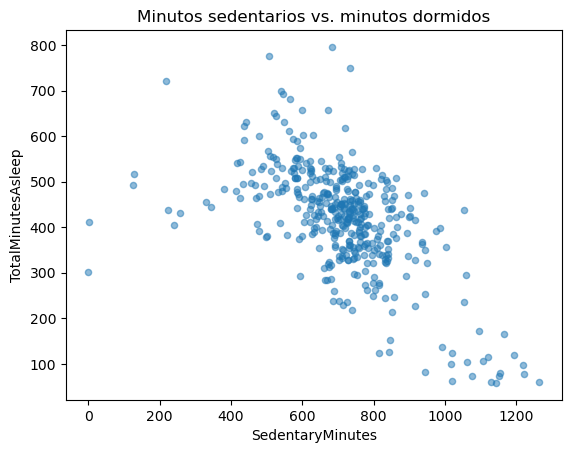

In [12]:
import matplotlib.pyplot as plt

# Gráfica 1: pasos promedio por día de la semana (con la tabla completa de actividad)
act["dia"] = act["fecha"].dt.day_name()
orden = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
act.groupby("dia")["TotalSteps"].mean().reindex(orden).plot(kind="bar")
plt.title("Pasos promedio por día de la semana")
plt.ylabel("Pasos")
plt.savefig("figures/pasos_por_dia.png", dpi=150, bbox_inches="tight")
plt.show()

# Gráfica 2: minutos sedentarios vs minutos dormidos (tabla unida)
df.plot(kind="scatter", x="SedentaryMinutes", y="TotalMinutesAsleep", alpha=0.5)
plt.title("Minutos sedentarios vs. minutos dormidos")
plt.savefig("figures/sedentarios_vs_sueno.png", dpi=150, bbox_inches="tight")
plt.show()

1st graph
* De lunes a sábado el promedio ronda los 7,200-7,800 pasos.
* El domingo baja a unos 6,600, el más bajo de la semana.
* Las diferencias son modestas y vienen de solo 35 usuarios

2da graph
* los puntos bajas hacia la derecha, lo que puede decir que más minutos sedentario = menos sueño
* los 0 pueden ser días donde no se usó el reloj o se descargó

medir la asociación y guardar las figuras

In [13]:
import os
os.makedirs("figures", exist_ok=True)

print("Días con 0 sedentarios:", (df["SedentaryMinutes"] == 0).sum())
print(df[["SedentaryMinutes", "TotalMinutesAsleep"]].corr())

#os.makedirs(..., exist_ok=True) crea la carpeta figures/ si no existe
#.corr() da un número entre -1 y 1 que resume qué tan juntas se mueven las dos columnas
#      (cerca de -1 significa una relación negativa más fuerte) 

Días con 0 sedentarios: 1
                    SedentaryMinutes  TotalMinutesAsleep
SedentaryMinutes            1.000000           -0.601073
TotalMinutesAsleep         -0.601073            1.000000


* los días con más tiempo sedentario tienden a tener menos sueño
* las dos variables se mueven en direcciones opuestas

definir “día de baja actividad”

In [14]:
# Día de baja actividad = menos de 5,000 pasos (umbral común para estilo de vida sedentario)
df["baja_actividad"] = (df["TotalSteps"] < 5000).astype(int)

print(df["baja_actividad"].value_counts())
print(df["baja_actividad"].mean().round(3))

#.astype(int) lo convierte en 1 (baja actividad) y 0 (no)
#.value_counts() cuenta cuántos días hay de cada tipo
#.mean() de una columna de 0 y 1, da proporción de días de baja actividad

baja_actividad
0    314
1     96
Name: count, dtype: int64
0.234


regresión logística

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

# Predictores: sueño y día de la semana (nada de pasos ni minutos activos)
df["despierto_en_cama"] = df["TotalTimeInBed"] - df["TotalMinutesAsleep"]
df["domingo"] = (df["fecha"].dt.dayofweek == 6).astype(int)

X = df[["TotalMinutesAsleep", "despierto_en_cama", "domingo"]]
y = df["baja_actividad"]
grupos = df["Id"]

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# Validación por usuario: ningún usuario aparece en entrenamiento y prueba a la vez
prob = cross_val_predict(modelo, X, y, groups=grupos,
                         cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
print("AUC:", round(roc_auc_score(y, prob), 3))

# Coeficientes (modelo ajustado con todos los datos)
modelo.fit(X, y)
coefs = modelo[-1].coef_[0]
print(dict(zip(X.columns, coefs.round(3))))

# LogisticRegression es el modelo
# StandardScaler pone las variables en la misma escala antes de entrenar
# make_pipeline encadena los dos pasos para que se ejecuten juntos
# max_iter=1000 le da más intentos para encontrar los pesos, para que no se detenga antes de terminar

AUC: 0.447
{'TotalMinutesAsleep': 0.396, 'despierto_en_cama': -0.001, 'domingo': 0.139}


AUC abajo de 0.5: 0.447 es ruido: el modelo no aprendió nada que sirva con usuarios nuevos

*Conclusión:*
Con minutos dormidos, minutos despierto en cama y día de la semana como predictores, la regresión logística con validación agrupada por usuario obtuvo un AUC de 0.45, sin capacidad predictiva por encima del azar. Los datos de sueño de un día no bastan para predecir días de baja actividad en este conjunto de 24 usuarios.